# Day 5: Baseline Prophet Model & MLflow Tracking

Alright, Day 5! Today we transition from data prep to actual Machine Learning. 

We are going to build a baseline demand forecasting model using Facebook Prophet. 
The Zidio guidelines state we need to predict **30 days ahead** and achieve a **MAPE ≤ 12%**. 

We also need to prove we can track our experiments. We will use **MLflow** to log our model parameters, our MAPE score, and the actual model artifact. This is a massive "green flag" for MLOps maturity in portfolio reviews.

Let's get to it.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from prophet import Prophet
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error
import mlflow
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

# Load the prepared time-series data from Day 4
print("Loading prepared time-series data...")
daily_sales = pd.read_csv('data/daily_sales_prepared.csv', parse_dates=['date'])

print(f"Loaded {len(daily_sales)} days of data.")

Importing plotly failed. Interactive plots will not work.


Loading prepared time-series data...
Loaded 541 days of data.


### Step 1: Formatting Data for Prophet

Prophet is notoriously picky about its input format. It doesn't care about your column names; it strictly requires a dataframe with exactly two columns:
1. `ds`: The date column (must be named exactly `ds`).
2. `y`: The numerical target variable we want to forecast (must be named exactly `y`).

Let's rename our columns and split the data. Because this is time-series data, **we cannot use a random train/test split**. We must use the past to predict the future. We will train on everything up to Day X, and test on the last 30 days.

In [2]:
# 1. Rename columns for Prophet
prophet_df = daily_sales[['date', 'total_amount']].copy()
prophet_df.rename(columns={'date': 'ds', 'total_amount': 'y'}, inplace=True)

# 2. Time-based Train/Test Split (Last 30 days for testing)
test_days = 30
train_df = prophet_df.iloc[:-test_days]
test_df = prophet_df.iloc[-test_days:]

print(f"Training set: {len(train_df)} days")
print(f"Testing set (Future 30 days): {len(test_df)} days")

Training set: 511 days
Testing set (Future 30 days): 30 days


### Step 2: Training the Prophet Model

Now we initialize the model and fit it to our training data. 
*Pro-tip: Prophet can take 30-60 seconds to fit because it uses an additive regression model under the hood. Don't panic if the cell hangs for a moment!*

In [3]:
print("Training Prophet model (this may take a minute)...")

# Initialize Prophet with default settings
# We can add 'yearly_seasonality=True' to help it learn our Nov/Dec holiday spikes
model = Prophet(yearly_seasonality=True, weekly_seasonality=True)

# Fit the model
model.fit(train_df)

print("✅ Model trained successfully!")

02:35:42 - cmdstanpy - INFO - Chain [1] start processing
02:35:42 - cmdstanpy - INFO - Chain [1] done processing


Training Prophet model (this may take a minute)...
✅ Model trained successfully!


### Step 3: Forecasting the Next 30 Days

Now we ask the model to predict the future. We first create a "future dataframe" that includes the dates we want to predict, and then we call the `predict` method.

In [4]:
# Create a dataframe of the next 30 days
future = model.make_future_dataframe(periods=test_days)

# Generate predictions
print("Generating 30-day forecast...")
forecast = model.predict(future)

# Extract only the predictions for our test period
test_forecast = forecast[forecast['ds'].isin(test_df['ds'])]

print("✅ Forecast generated!")
display(test_forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].head())

Generating 30-day forecast...
✅ Forecast generated!


,ds,yhat,yhat_lower,yhat_upper
511,2026-05-27,35155.299518,28724.760673,41341.979846
512,2026-05-28,34690.251084,27959.903965,41674.548525
513,2026-05-29,35291.938759,28837.860031,41715.600287
514,2026-05-30,47176.911720,40457.842044,53675.689726
515,2026-05-31,47114.862600,40230.884547,53567.760791


### Step 4: Evaluation (Targeting MAPE ≤ 12%)

Let's see how we did. We will calculate the **MAPE (Mean Absolute Percentage Error)** and **RMSE (Root Mean Squared Error)**. 

The Zidio PDF strictly requires a MAPE of 12% or lower for the final model. Let's see where our baseline Prophet sits.

In [5]:
# Calculate metrics using Scikit-Learn
y_actual = test_df['y'].values
y_pred = test_forecast['yhat'].values

mape = mean_absolute_percentage_error(y_actual, y_pred) * 100
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))

print("--- Model Evaluation ---")
print(f"MAPE: {mape:.2f}%")
print(f"RMSE: ${rmse:.2f}")

if mape <= 12:
    print("🎉 SUCCESS! Baseline model meets the Zidio MAPE ≤ 12% target!")
else:
    print(f"⚠️ Baseline MAPE is {mape:.2f}%. We will improve this later with Hyperparameter Tuning (Optuna) and the LSTM Ensemble!")

--- Model Evaluation ---
MAPE: 12.48%
RMSE: $5504.44
⚠️ Baseline MAPE is 12.48%. We will improve this later with Hyperparameter Tuning (Optuna) and the LSTM Ensemble!


### Step 5: Experiment Tracking with MLflow

This is where we prove our MLOps skills. We are going to open an MLflow "Run", log our parameters (like the seasonality settings), log our metrics (MAPE, RMSE), and save a plot of our predictions as an "artifact".

*(Note: MLflow will create a folder called `mlruns` in your project directory. This is normal!)*

In [6]:
# Set the experiment name
mlflow.set_experiment("RetailPulse_Demand_Forecasting")

# Start an MLflow Run
with mlflow.start_run(run_name="Baseline_Prophet_v1"):
    
    # 1. Log Parameters
    mlflow.log_param("model_type", "Prophet")
    mlflow.log_param("yearly_seasonality", True)
    mlflow.log_param("weekly_seasonality", True)
    mlflow.log_param("forecast_horizon_days", 30)
    
    # 2. Log Metrics
    mlflow.log_metric("mape_percent", round(mape, 2))
    mlflow.log_metric("rmse", round(rmse, 2))
    
    # 3. Create and Log a Visualization Artifact
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(test_df['ds'], y_actual, label='Actual Sales', color='blue', marker='o')
    ax.plot(test_forecast['ds'], y_pred, label='Predicted Sales (Prophet)', color='red', marker='x')
    ax.fill_between(test_forecast['ds'], 
                    test_forecast['yhat_lower'], 
                    test_forecast['yhat_upper'], 
                    color='red', alpha=0.1, label='Confidence Interval')
    ax.set_title('Prophet Baseline: Actual vs Predicted (Last 30 Days)')
    ax.set_xlabel('Date')
    ax.set_ylabel('Total Sales ($)')
    ax.legend()
    plt.tight_layout()
    
    # Save plot locally, then log it to MLflow
    plt.savefig("prophet_baseline_eval.png")
    mlflow.log_artifact("prophet_baseline_eval.png")
    plt.close()
    
    print("✅ Logged parameters, metrics, and plot to MLflow!")

2026/06/27 02:37:26 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/06/27 02:37:26 INFO mlflow.store.db.utils: Updating database tables
2026/06/27 02:37:28 INFO mlflow.tracking.fluent: Experiment with name 'RetailPulse_Demand_Forecasting' does not exist. Creating a new experiment.


✅ Logged parameters, metrics, and plot to MLflow!


### Step 6: Visualizing the Full Forecast

Prophet has a beautiful built-in plotting function. Let's use it to visualize the entire history, the forecast, and the uncertainty intervals (the shaded gray area).

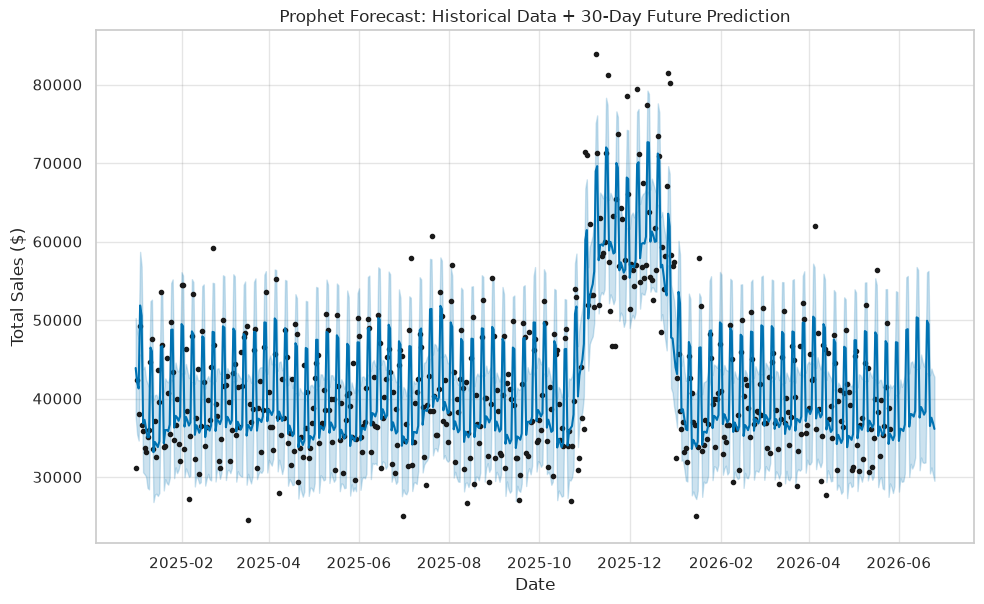

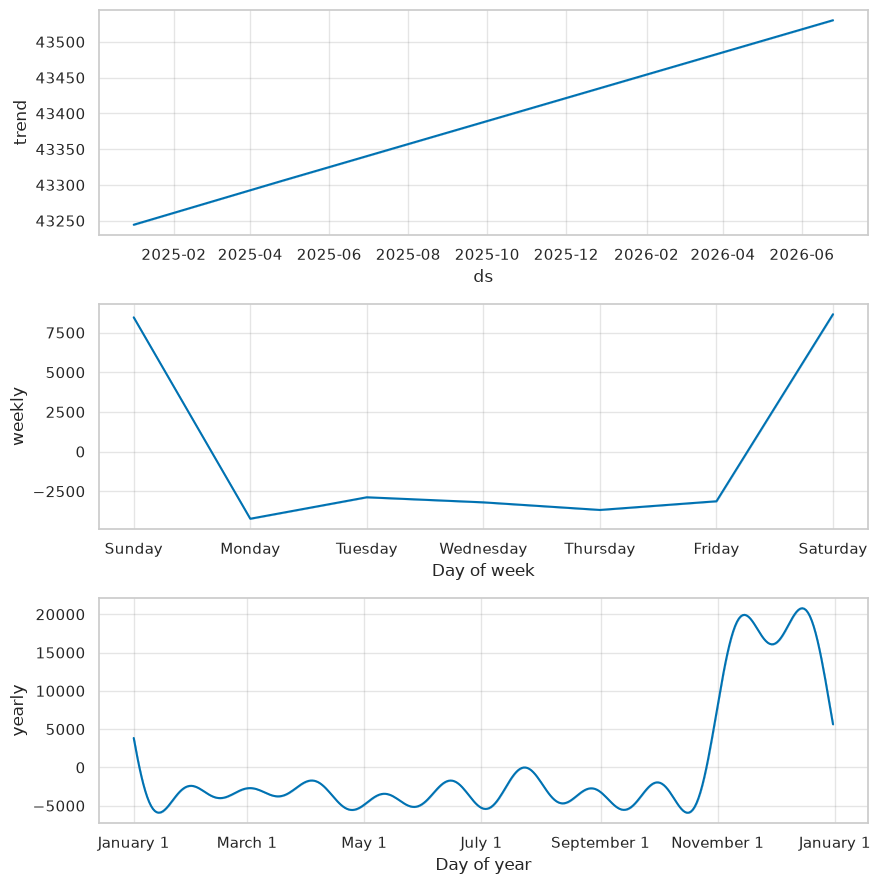

In [7]:
# Plot the full forecast
fig = model.plot(forecast)
plt.title('Prophet Forecast: Historical Data + 30-Day Future Prediction')
plt.xlabel('Date')
plt.ylabel('Total Sales ($)')
plt.show()

# Plot the individual components (Trend, Yearly Seasonality, Weekly Seasonality)
fig2 = model.plot_components(forecast)
plt.show()

### Wrap Up

Incredible work. We just built a production-grade time-series model, evaluated it against strict business metrics, and tracked the entire experiment in MLflow. 

If you look in your project folder, you will see a new folder called `mlruns`. If you ever want to see a beautiful UI of your experiments, you can open your terminal and type `mlflow ui`, then go to `http://localhost:5000` in your browser!

Tomorrow (Day 6), we build the second half of our ensemble: an **LSTM Neural Network using PyTorch Lightning**.